# Plant-off hours — Idle and Shut-down at rest: temperature, timing and signals (all 39 days)

The plant is **off** when there is no current, no EAPH heater and no air flow. Since the 2026-10-14 decision
(`../01_docs/operational-modes.md` §1) those hours carry one of three labels:

| Label | Meaning |
|---|---|
| **Shut-down, plant off at ambient** | stack within 30 K of ambient (ambient + 30 K ≈ 40–48 °C) |
| **Shut-down, natural cooling (air off)** | stack still warm, a Shut-down came before it (its natural-cooling tail) |
| **Idle** | stack still warm, no Shut-down before it (first file, or after a heat-up that stopped) |

A plant-off pause *between two parts of one heat-up* (2026-03-17 20:08 → 03-18 07:10) is not counted here: it is
**Start-up, heat-up interrupted (plant off)** (user confirmed 2026-10-14). It still enters the cooling fit of §5,
which selects stretches by signals, not by label.

This notebook looks only at those hours (it replaces the earlier *Cold / idle* study):

1. **Inventory**: every plant-off episode, with what came before and after it.
2. **What the hours contain**: minutes per label, and a check of the 30 K "near ambient" margin.
3. **Temperature**: stack level, ambient, spread across thermocouples, and balance-of-plant (BOP) parts.
4. **Cooling physics**: how fast the stack loses heat with the heater and the air off (Newton's law, time constant τ).
5. **Timings**: episode durations, clock times, and the campaign calendar.
6. **Leaving the off state**: the order in which the signals switch on at a start-up.
7. **Signal baseline**: levels and noise of each signal while the plant is off at ambient (input for synthetic data).

**Data:** stage and operation labels come from `04_synthetic_data/library/traces_1min.parquet`, rebuilt by
`build_library.py` from `operating_states.py` on 2026-10-14 after the Idle change. The extra signals (ambient probes,
BOP temperatures, gas flows, supply pressures) are read from `02_data/downsampled/*_10s.parquet` and averaged to
1 min. Tables and figures are saved to `cold_idle/`.


In [1]:
import glob
import sys
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "scripts")  # helper modules live in 03_data_analysis/scripts/
import operating_states as ops

pd.set_option("display.max_rows", 120)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

ROOT = Path("..").resolve()
LIB = ROOT / "04_synthetic_data" / "library"
OUT = Path("cold_idle")
OUT.mkdir(exist_ok=True)
MAX_BRIDGE_MIN = (
    60  # a logger gap up to this long does not split an episode (as build_library.py)
)

# categorical slots (validated, light surface): blue, orange, aqua, yellow
SUB_COLORS = {
    "Shut-down: plant off at ambient": "#2a78d6",
    "Shut-down: natural-cooling tail": "#eb6834",
    "Idle: after a stopped heat-up": "#1baf7a",
    "Idle: no history in the data": "#eda100",
}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "lines.linewidth": 1.4,
        "font.size": 9,
    }
)

## 1. Load labels and signals

Ambient temperature is not measured directly: the ICA list has no ambient or container probe. The four
supply-line probes in the fuel-processing module (FPM) are used as an **ambient proxy**: `TIR_1_1_1` (air),
`TIR_1_2_1` (POx air), `TIR_1_3` (purge gas) and `TIR_1_4_1` (fuel). They sit on cold supply pipes, far from the
stack, and stay around 15 °C whatever the stack does. The proxy is built exactly as in `operating_states.py`
(−1 fill values dropped, 60-min rolling median), so "near ambient" here is the same test the labels use.
`TIR_7_05` (roof exhaust, no flow while the plant is off) is kept as a second, outdoor-side reference. Section 4.2
shows that the FPM probes sit in a conditioned space: after days off the stack settles *below* them, so the stack's
real surroundings are colder. Both references are carried through the cooling fit (§5).


In [2]:
tr = pd.read_parquet(LIB / "traces_1min.parquet")

AMB = ops.AMB_COLS
BOP = {
    "EAPH inlet (TIR_2_05)": "TIR_2_05",
    "EAPH outlet / cathode inlet (TIRC_2_06)": "TIRC_2_06",
    "EAPH element, safety (TIRZ_8_1_1)": "TIRZ_8_1_1",
    "Reformer catalyst in (TIRC_3_07)": "TIRC_3_07",
    "Reformer catalyst out (TIRC_3_15)": "TIRC_3_15",
    "Afterburner (TIRC_5_09)": "TIRC_5_09",
    "ERH housing heater (TIRC_5_17)": "TIRC_5_17",
    "Recycle gas (TIR_6_01)": "TIR_6_01",
    "APH exhaust outlet (TIR_7_04)": "TIR_7_04",
    "Roof exhaust (TIR_7_05)": "TIR_7_05",
}
FLOW = {
    "air_1": "ct_FIRC_111_PV_ProcessValue",
    "air_2": "ct_FIRC_112_PV_ProcessValue",
    "pox_air": "ct_FIRC_12_PV_ProcessValue",
    "N2": "ct_FIRC_13_PV_ProcessValue",
    "fuel": "ct_FIRC_14_PV_ProcessValue",
    "H2": "ct_FIRC_15_PV_ProcessValue",
}
PRESS = {
    "p_air_supply_bar": "PIR_1_1_1",
    "p_N2_purge_bar": "PIR_1_3_2",
    "p_H2_supply_bar": "PIR_1_5",
}
VOLT = [f"PLC_hostSetp_ctrl_ctEIRC4{i}_rVoltMonitor" for i in range(1, 6)]
cols = (
    AMB
    + list(BOP.values())
    + list(FLOW.values())
    + list(PRESS.values())
    + VOLT
    + ["EIRC_2_01_ActV_rMas_MainsVoltage"]
)

parts = []
for f in sorted(glob.glob(str(ROOT / "02_data" / "downsampled" / "*_10s.parquet"))):
    r = pd.read_parquet(f, columns=["Date Time"] + cols)
    r.index = pd.to_datetime(r.pop("Date Time"))
    r = r.apply(pd.to_numeric, errors="coerce")
    # ambient proxy as in operating_states.load_signals (per day file)
    r["T_amb_C"] = r[AMB].where((r[AMB] != -1) & (r[AMB] < 60)).median(axis=1)
    r = r.resample("1min").mean()
    r["T_amb_C"] = (
        r["T_amb_C"]
        .rolling(60, center=True, min_periods=1)
        .median()
        .fillna(ops.T_AMB_DEFAULT)
    )
    parts.append(r)
sig = pd.concat(parts)

d = tr.join(sig)
for k, c in FLOW.items():
    d[k] = d[c]
d["air_flow"] = d["air_1"] + d["air_2"]
for k, c in PRESS.items():
    d[k] = d[c]
d["V_stack_mean"] = d[VOLT].mean(axis=1)
d["T_spread_K"] = d["T_stack_max_C"] - d["T_stack_min_C"]
d["excess_K"] = d["T_stack_C"] - d["T_amb_C"]
# rates on a gap-free minute grid, so differences never jump across a missing day
g = d["T_stack_C"].asfreq("1min")
d["dTdt_C_per_h"] = (g.shift(-30) - g.shift(30)).reindex(d.index)
d["dTdt_20min_C_per_h"] = ((g.shift(-10) - g.shift(10)) * 3).reindex(d.index)

d["off"] = (d.stage == "Idle") | d.operation.isin([ops.AT_AMBIENT, ops.TAIL])
print(
    f"{len(d):,} labelled minutes, {d.index.normalize().nunique()} days, "
    f"{d.off.sum():,} plant-off minutes ({d.off.mean():.1%})"
)
d.stage.value_counts().rename("minutes").to_frame().assign(
    hours=lambda x: (x.minutes / 60).round(1)
)

54,810 labelled minutes, 39 days, 9,082 plant-off minutes (16.6%)


,minutes,hours
stage,,
Shut-down,23131,385.5
Hot standby,17856,297.6
Start-up,9568,159.5
Thermal adjustment,2729,45.5
Idle,1258,21.0
Part load,268,4.5


## 2. Inventory of plant-off episodes

An **episode** is a contiguous run of plant-off minutes (any of the three labels). Logger gaps up to 60 min are
bridged and episodes that cross midnight are joined, as in `build_library.py`. The previous / next label is the
minute just before / after the episode; `file edge` means the episode starts or ends at a missing-day boundary, so
its true length is unknown and the duration is a lower bound.


In [3]:
step = d.index.to_series().diff()
new_ep = (d.off != d.off.shift()) | (step > pd.Timedelta(minutes=MAX_BRIDGE_MIN))
d["off_ep"] = new_ep.cumsum()
lab = d.stage + ", " + d.operation

rows = []
for k, g in d[d.off].groupby("off_ep"):
    i0, i1 = d.index.get_loc(g.index[0]), d.index.get_loc(g.index[-1])
    gap_in = i0 == 0 or g.index[0] - d.index[i0 - 1] > pd.Timedelta(
        minutes=MAX_BRIDGE_MIN
    )
    gap_out = i1 == len(d) - 1 or d.index[i1 + 1] - g.index[-1] > pd.Timedelta(
        minutes=MAX_BRIDGE_MIN
    )
    T = g.T_stack_C.dropna()
    rows.append(
        {
            "episode_id": g.index[0].strftime("%Y%m%d_%H%M_off"),
            "off_ep": k,
            "start": g.index[0],
            "end": g.index[-1] + pd.Timedelta("1min"),
            "duration_h": len(g) / 60,
            "T_start_C": T.iloc[0],
            "T_end_C": T.iloc[-1],
            "T_min_C": T.min(),
            "T_max_C": T.max(),
            "dTdt_mean_C_per_h": g.dTdt_C_per_h.mean(),
            "prev_stage": None if gap_in else d.stage.iloc[i0 - 1],
            "prev_label": "file edge" if gap_in else lab.iloc[i0 - 1],
            "next_stage": None if gap_out else d.stage.iloc[i1 + 1],
            "starts_at_run_edge": gap_in,
            "ends_at_run_edge": gap_out,
            "labels": " -> ".join(lab[g.index][lab[g.index] != lab[g.index].shift()]),
        }
    )
ce = pd.DataFrame(rows)
ce["cut_at_file_edge"] = ce.starts_at_run_edge | ce.ends_at_run_edge
inv = ce.drop(columns=["off_ep"])
inv[inv.select_dtypes("number").columns] = inv.select_dtypes("number").round(2)
inv.to_csv(OUT / "episodes.csv", index=False)
inv.drop(columns=["starts_at_run_edge", "ends_at_run_edge"])

,episode_id,start,end,duration_h,T_start_C,T_end_C,T_min_C,T_max_C,dTdt_mean_C_per_h,prev_stage,prev_label,next_stage,labels,cut_at_file_edge
0,20251030_0000_off,2025-10-30 00:00:00,2025-10-30 11:29:00,11.48,155.77,138.04,138.04,155.77,-1.60,NaN,file edge,Start-up,"Idle, Natural cooling (heater off, no air)",True
1,20251030_1431_off,2025-10-30 14:31:00,2025-10-31 00:00:00,9.48,199.14,181.11,181.11,199.14,-1.82,Start-up,"Start-up, Heat-up (EAPH on)",NaN,"Idle, Heat-up stopped - settling / natural coo...",True
2,20251113_0000_off,2025-11-13 00:00:00,2025-11-13 10:47:00,10.78,10.18,10.10,9.85,10.29,0.06,NaN,file edge,Start-up,"Shut-down, Plant off at ambient",True
3,20251118_0732_off,2025-11-18 07:32:00,2025-11-19 00:00:00,16.47,24.71,22.64,22.60,24.81,-0.13,Shut-down,"Shut-down, Cool-down (air flow on)",NaN,"Shut-down, Plant off at ambient",True
4,20260130_0000_off,2026-01-30 00:00:00,2026-01-30 10:10:00,10.17,6.10,4.03,3.40,6.10,-0.19,NaN,file edge,Start-up,"Shut-down, Plant off at ambient",True
5,20260130_2115_off,2026-01-30 21:15:00,2026-01-31 08:09:00,10.90,197.26,175.08,175.08,197.26,-1.87,Shut-down,"Shut-down, Cool-down (air flow on)",Start-up,"Shut-down, Natural cooling (air off)",False
6,20260206_0923_off,2026-02-06 09:23:00,2026-02-06 13:27:00,4.07,46.27,45.28,45.26,46.31,-0.18,Shut-down,"Shut-down, Cool-down (air flow on)",Start-up,"Shut-down, Plant off at ambient",False
7,20260213_0000_off,2026-02-13 00:00:00,2026-02-13 14:32:00,14.53,14.98,14.53,13.90,15.22,-0.01,NaN,file edge,Start-up,"Shut-down, Plant off at ambient",True
8,20260217_0742_off,2026-02-17 07:42:00,2026-02-17 16:56:00,9.23,210.00,191.12,190.34,210.00,-2.04,Shut-down,"Shut-down, Cool-down (air flow on)",Start-up,"Shut-down, Natural cooling (air off)",False
9,20260301_0000_off,2026-03-01 00:00:00,2026-03-01 09:05:00,9.08,29.37,27.64,27.61,29.39,-0.22,NaN,file edge,Start-up,"Shut-down, Plant off at ambient",True


## 3. What the plant-off hours contain

Each plant-off minute is sorted by its label; Idle is split by what came before its episode:

| Sub-type | Label | Test |
|---|---|---|
| Shut-down: plant off at ambient | Shut-down, plant off at ambient | stack ≤ ambient + 30 K |
| Shut-down: natural-cooling tail | Shut-down, natural cooling (air off) | warm, a Shut-down came before it |
| Idle: after a stopped heat-up | Idle | warm, episode follows a Start-up that stopped below Hot standby |
| Idle: no history in the data | Idle | warm, episode starts at a file edge (first file) |


In [4]:
c = d[d.off].copy()
c["episode_id"] = c.off_ep.map(ce.set_index("off_ep").episode_id)
prev = c.off_ep.map(ce.set_index("off_ep").prev_stage)
names = list(SUB_COLORS)
c["subtype"] = np.select(
    [
        c.operation == ops.AT_AMBIENT,
        c.operation == ops.TAIL,
        (c.stage == "Idle") & (prev == "Start-up"),
    ],
    names[:3],
    default=names[3],
)

sub = (
    c.groupby("subtype")
    .agg(
        minutes=("T_stack_C", "size"),
        T_median_C=("T_stack_C", "median"),
        T_min_C=("T_stack_C", "min"),
        T_max_C=("T_stack_C", "max"),
        excess_median_K=("excess_K", "median"),
        dTdt_median_C_per_h=("dTdt_C_per_h", "median"),
        episodes=("episode_id", "nunique"),
    )
    .reindex(names)
)
sub.insert(1, "hours", (sub.minutes / 60).round(1))
sub.insert(2, "share", (sub.minutes / len(c)).round(3))
sub.round(2).to_csv(OUT / "subtypes.csv")
sub.round(2)

,minutes,hours,share,T_median_C,T_min_C,T_max_C,excess_median_K,dTdt_median_C_per_h,episodes
subtype,,,,,,,,,
Shut-down: plant off at ambient,4659,77.6,0.51,23.08,3.40,46.31,6.50,-0.10,8
Shut-down: natural-cooling tail,3165,52.8,0.35,63.40,38.04,264.26,53.95,-0.56,7
Idle: after a stopped heat-up,569,9.5,0.06,190.88,181.11,199.14,172.91,-2.04,1
Idle: no history in the data,689,11.5,0.08,146.46,138.04,155.77,128.96,-1.49,1


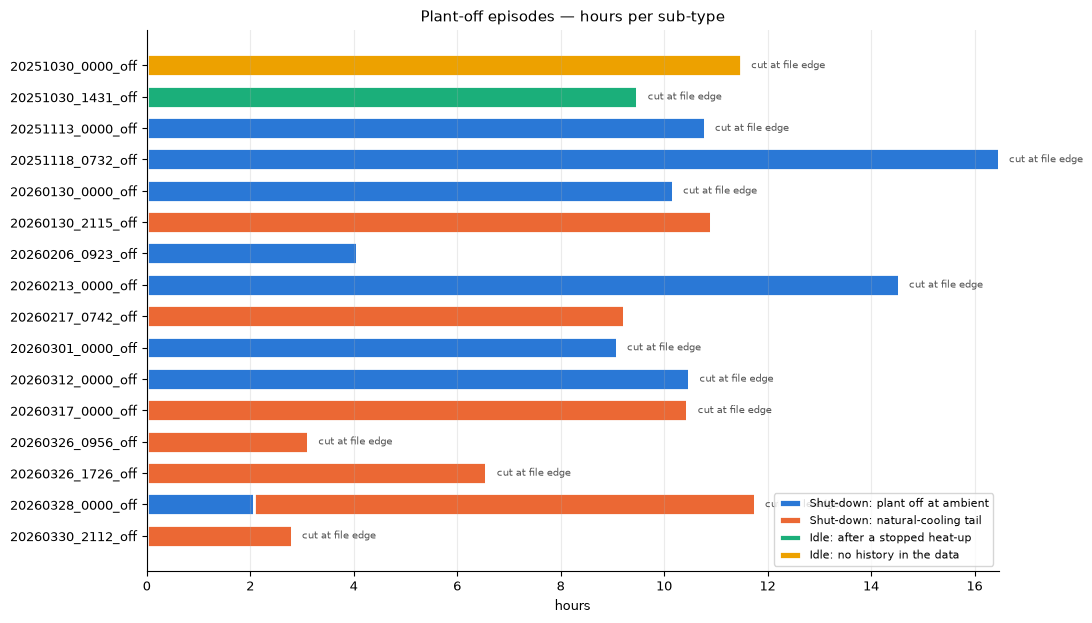

In [5]:
per_ep = (
    c.groupby(["episode_id", "subtype"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=names, fill_value=0)
    / 60
)
per_ep = per_ep.loc[ce.episode_id]
fig, ax = plt.subplots(figsize=(11, 0.3 * len(per_ep) + 1.5))
left = np.zeros(len(per_ep))
for n in names:
    ax.barh(
        per_ep.index,
        per_ep[n],
        left=left,
        color=SUB_COLORS[n],
        label=n,
        height=0.7,
        edgecolor="white",
        linewidth=2,
    )
    left += per_ep[n].values
for y, cut in enumerate(ce.cut_at_file_edge):
    if cut:
        ax.text(
            left[y] + 0.2, y, "cut at file edge", va="center", fontsize=7, color="#555"
        )
ax.invert_yaxis()
ax.set_xlabel("hours")
ax.grid(axis="y", visible=False)
ax.set_title("Plant-off episodes — hours per sub-type")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "subtypes_per_episode.png", dpi=130)
plt.show()

**Is 30 K a sensible "near ambient" margin?** Minutes that would count as *at ambient* for other margins, out of all
plant-off minutes that are not Idle (Idle stays Idle while the stack is warm, whatever the margin, only its end
moves). The stack excess over the proxy in the at-ambient minutes is shown too.


In [6]:
sd = c[c.stage == "Shut-down"]
margin = pd.DataFrame(
    {
        m: {
            "at-ambient hours": (sd.excess_K <= m).sum() / 60,
            "natural-cooling-tail hours": (sd.excess_K > m).sum() / 60,
        }
        for m in (10, 20, 30, 40, 50)
    }
).T.round(1)
margin.index.name = "margin_K"
print(
    "stack − ambient proxy in the at-ambient minutes (K): "
    + ", ".join(
        f"p{q}: {c[c.subtype == names[0]].excess_K.quantile(q / 100):.1f}"
        for q in (5, 50, 95)
    )
)
margin

stack − ambient proxy in the at-ambient minutes (K): p5: -10.4, p50: 6.5, p95: 28.4


,at-ambient hours,natural-cooling-tail hours
margin_K,,
10,51.8,78.3
20,71.4,58.7
30,77.5,52.6
40,96.8,33.2
50,97.5,32.6


## 4. Temperature

### 4.1 Every episode: stack, thermocouple band and ambient

Black = stack median, grey band = coldest to hottest valid stack thermocouple, blue = ambient proxy
(FPM supply lines), dotted = roof exhaust `TIR_7_05`. The dashed orange line is ambient + 30 K, the near-ambient
limit used by the labels.


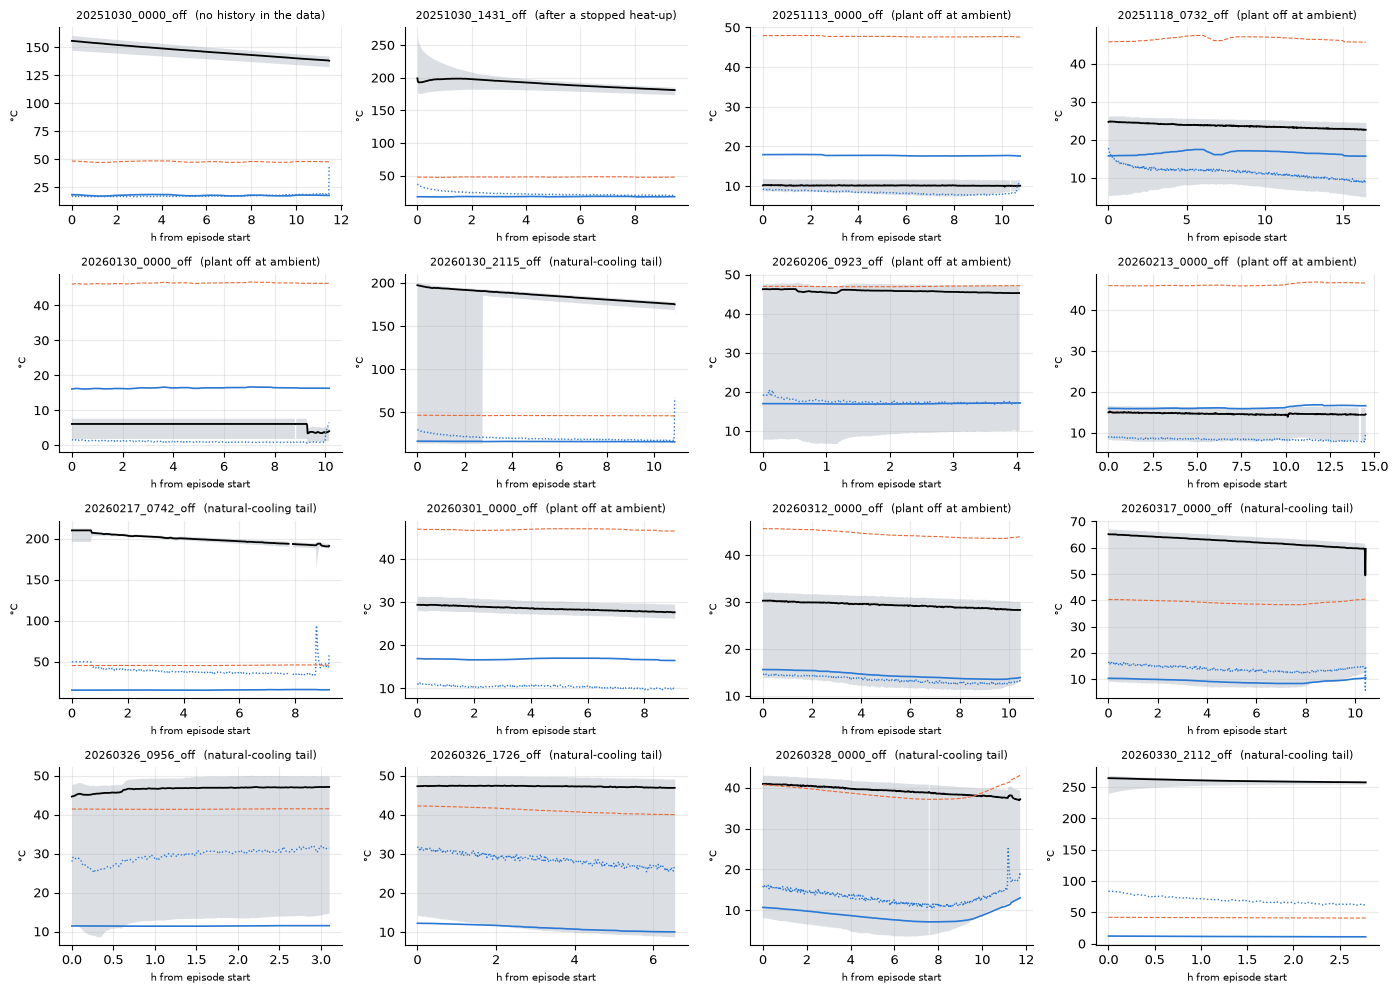

In [7]:
ids = list(ce.episode_id)
ncol = 4
nrow = int(np.ceil(len(ids) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(14, 2.5 * nrow))
for a, eid in zip(axs.flat, ids):
    e = c[c.episode_id == eid]
    h = (e.index - e.index[0]).total_seconds() / 3600
    a.fill_between(
        h, e.T_stack_min_C, e.T_stack_max_C, color="#9aa5b1", alpha=0.35, lw=0
    )
    a.plot(h, e.T_stack_C, color="k", lw=1.3)
    a.plot(h, e.T_amb_C, color="#2a78d6", lw=1.2)
    a.plot(h, e.TIR_7_05, color="#2a78d6", lw=1, ls=":")
    a.plot(h, e.T_amb_C + ops.DT_AMBIENT, color="#eb6834", lw=0.8, ls="--")
    a.set_title(f"{eid}  ({e.subtype.mode().iat[0].split(': ')[1]})", fontsize=8)
    a.set_xlabel("h from episode start", fontsize=7)
    a.set_ylabel("°C", fontsize=7)
for a in axs.flat[len(ids) :]:
    a.axis("off")
fig.tight_layout()
fig.savefig(OUT / "episodes_temperature.png", dpi=120)
plt.show()

### 4.2 How far above ambient does the stack settle?

For the at-ambient minutes: the stack excess over the ambient proxy and over the roof exhaust, the thermocouple
spread, and the slope.


In [8]:
s = c[c.subtype == names[0]].copy()
s["excess_roof_K"] = s.T_stack_C - s.TIR_7_05
settled = (
    s.groupby("episode_id")
    .agg(
        hours=("T_stack_C", lambda x: len(x) / 60),
        T_stack_median_C=("T_stack_C", "median"),
        T_amb_median_C=("T_amb_C", "median"),
        excess_median_K=("excess_K", "median"),
        roof_exhaust_median_C=("TIR_7_05", "median"),
        excess_over_roof_K=("excess_roof_K", "median"),
        spread_median_K=("T_spread_K", "median"),
        dTdt_median_C_per_h=("dTdt_C_per_h", "median"),
    )
    .round(2)
)
settled.loc["all at-ambient minutes"] = [
    len(s) / 60,
    s.T_stack_C.median(),
    s.T_amb_C.median(),
    s.excess_K.median(),
    s.TIR_7_05.median(),
    s.excess_roof_K.median(),
    s.T_spread_K.median(),
    s.dTdt_C_per_h.median(),
]
settled.round(2).to_csv(OUT / "settled_cold.csv")
settled.round(2)

,hours,T_stack_median_C,T_amb_median_C,excess_median_K,roof_exhaust_median_C,excess_over_roof_K,spread_median_K,dTdt_median_C_per_h
episode_id,,,,,,,,
20251113_0000_off,10.78,10.16,17.71,-7.58,8.32,1.83,3.56,-0.01
20251118_0732_off,16.47,23.63,16.47,6.74,11.72,12.04,18.33,-0.13
20260130_0000_off,10.17,6.10,16.40,-10.32,0.98,5.07,5.80,0.00
20260206_0923_off,4.07,45.73,16.99,28.77,17.38,28.31,38.32,-0.26
20260213_0000_off,14.53,14.60,16.03,-1.43,8.38,6.25,8.19,-0.05
20260301_0000_off,9.08,28.41,16.81,11.46,10.40,17.98,3.18,-0.19
20260312_0000_off,10.48,29.34,14.25,14.98,13.34,15.88,19.12,-0.19
20260328_0000_off,2.07,37.79,10.30,27.40,14.33,23.44,29.21,-0.31
all at-ambient minutes,77.65,23.08,16.48,6.50,9.97,11.74,8.33,-0.10


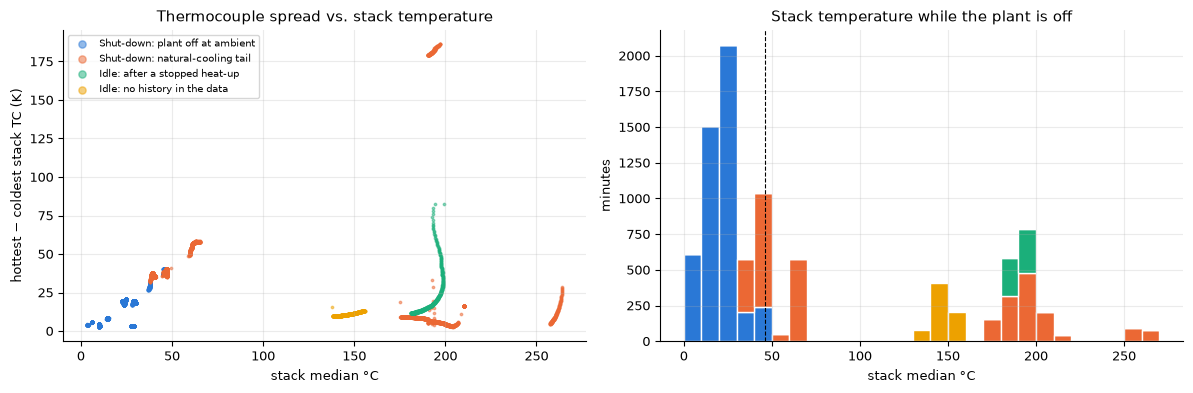

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for n in names:
    x = c[c.subtype == n]
    if len(x):
        ax[0].scatter(
            x.T_stack_C, x.T_spread_K, s=3, color=SUB_COLORS[n], label=n, alpha=0.5
        )
ax[0].set_xlabel("stack median °C")
ax[0].set_ylabel("hottest − coldest stack TC (K)")
ax[0].set_title("Thermocouple spread vs. stack temperature")
ax[0].legend(fontsize=7, markerscale=3)
bins = np.arange(0, 280, 10)
ax[1].hist(
    [c[c.subtype == n].T_stack_C.dropna() for n in names],
    bins=bins,
    stacked=True,
    color=[SUB_COLORS[n] for n in names],
    label=names,
    edgecolor="white",
    linewidth=1,
)
ax[1].set_xlabel("stack median °C")
ax[1].set_ylabel("minutes")
ax[1].set_title("Stack temperature while the plant is off")
ax[1].axvline(c.T_amb_C.median() + ops.DT_AMBIENT, color="k", lw=0.8, ls="--")
fig.tight_layout()
fig.savefig(OUT / "spread_and_histogram.png", dpi=130)
plt.show()

### 4.3 Balance-of-plant temperatures

Which parts are still warm while the plant is off? `excess ratio` = (part − ambient) / (stack − ambient), median
over the warm minutes. Below 1 the part is cooler than the stack (cools faster or sits outside the hot box); above 1
it holds more heat than the stack.

In [10]:
warm = c[c.subtype != names[0]]
rows = {}
for name, col in {"Stack median (TIR_4_6_*)": "T_stack_C", **BOP}.items():
    rows[name] = {
        "at ambient: median °C": s[col].median(),
        "warm: median °C": warm[col].median(),
        "warm: excess ratio vs stack": (
            (warm[col] - warm.T_amb_C) / (warm.T_stack_C - warm.T_amb_C)
        ).median(),
    }
bop = (
    pd.DataFrame(rows)
    .T.round(2)
    .sort_values("warm: excess ratio vs stack", ascending=False)
)
bop.to_csv(OUT / "bop_temperatures.csv")
bop

,at ambient: median °C,warm: median °C,warm: excess ratio vs stack
Stack median (TIR_4_6_*),23.08,148.20,1.00
EAPH outlet / cathode inlet (TIRC_2_06),21.99,147.73,0.99
Recycle gas (TIR_6_01),19.40,103.01,0.94
"EAPH element, safety (TIRZ_8_1_1)",20.35,128.06,0.91
ERH housing heater (TIRC_5_17),12.09,109.33,0.87
Afterburner (TIRC_5_09),12.99,103.30,0.83
Reformer catalyst out (TIRC_3_15),11.90,102.56,0.82
Reformer catalyst in (TIRC_3_07),12.14,102.79,0.82
EAPH inlet (TIR_2_05),19.60,84.90,0.80
APH exhaust outlet (TIR_7_04),12.40,29.79,0.22


## 5. Cooling physics with heater and air off

With no current, no heater and no air, the stack loses heat only through the insulation. Newton's law of cooling
then gives

$$T(t) = T_{amb} + (T_0 - T_{amb})\, e^{-t/\tau}$$

so ln(T − T_amb) falls on a straight line with slope −1/τ. The fit uses every stretch of ≥ 2 h with heater
< 0.2 kW, air flow < 50 ln/min, air pressure `PIR_2_02` ≤ 1, current < 1 A and stack ≥ 50 °C, **whatever its
label** (Idle or the Shut-down natural-cooling tail). The 50 °C floor keeps the fit away from the at-ambient minutes,
where T − T_amb is too small for a clean log. The same fit is applied to the BOP parts.


In [11]:
nat = (
    (d.air_flow < 50)
    & (d.P_EAPH_kW < 0.2)
    & (d.I_string_A < 1)
    & (d.P_air_in <= 1)
    & (d.T_stack_C >= 50)
)
step = d.index.to_series().diff() != pd.Timedelta("1min")
run = ((nat != nat.shift()) | step).cumsum()


def tau_fit(y, ta, h):
    z = np.log((y - ta).clip(lower=1))
    ok = z.notna() & np.isfinite(z)
    p = np.polyfit(h[ok], z[ok], 1)
    return -1 / p[0], np.corrcoef(h[ok], z[ok])[0, 1] ** 2


fits, bop_tau = [], []
for k, g in d[nat].groupby(run[nat]):
    if len(g) < 120:
        continue
    h = pd.Series((g.index - g.index[0]).total_seconds() / 3600, index=g.index)
    tau, r2 = tau_fit(g.T_stack_C, g.T_amb_C.mean(), h)
    tau_roof, _ = tau_fit(g.T_stack_C, g.TIR_7_05.mean(), h)
    fits.append(
        {
            "start": g.index[0],
            "end": g.index[-1],
            "hours": round(len(g) / 60, 1),
            "labels": ", ".join(f"{k} {v}" for k, v in g.stage.value_counts().items()),
            "T_from_C": g.T_stack_C.iloc[0],
            "T_to_C": g.T_stack_C.iloc[-1],
            "T_amb_C": g.T_amb_C.mean(),
            "rate_C_per_h": (g.T_stack_C.iloc[-1] - g.T_stack_C.iloc[0]) / h.iloc[-1],
            "tau_h": tau,
            "R2": r2,
            "T_roof_C": g.TIR_7_05.mean(),
            "tau_h_roof_ambient": tau_roof,
        }
    )
    for name, col in BOP.items():
        if g[col].notna().mean() > 0.9 and (g[col] - g.T_amb_C).median() > 20:
            t_b, r_b = tau_fit(g[col], g.T_amb_C.mean(), h)
            bop_tau.append({"part": name, "start": g.index[0], "tau_h": t_b, "R2": r_b})
fits = pd.DataFrame(fits)
fits[fits.select_dtypes("number").columns] = fits.select_dtypes("number").round(2)
fits.to_csv(OUT / "cooling_tau_stack.csv", index=False)
fits

,start,end,hours,labels,T_from_C,T_to_C,T_amb_C,rate_C_per_h,tau_h,R2,T_roof_C,tau_h_roof_ambient
0,2025-10-30 00:00:00,2025-10-30 11:27:00,11.5,Idle 688,155.77,138.27,17.92,-1.53,85.35,1.00,17.51,85.62
1,2025-10-30 14:31:00,2025-10-30 23:59:00,9.5,Idle 569,199.14,181.11,18.03,-1.90,88.14,0.93,22.66,85.77
2,2026-01-30 21:06:00,2026-01-31 08:06:00,11.0,Shut-down 661,198.20,175.46,16.48,-2.07,89.25,1.00,20.53,87.11
3,2026-02-17 07:40:00,2026-02-17 14:56:00,7.3,Shut-down 437,209.99,194.44,15.37,-2.14,91.06,0.97,39.34,79.35
4,2026-03-17 00:00:00,2026-03-17 10:24:00,10.4,Shut-down 625,65.17,58.59,9.27,-0.63,99.29,1.00,14.01,90.43
5,2026-03-17 20:08:00,2026-03-18 07:05:00,11.0,Start-up 658,188.40,169.30,9.07,-1.74,83.71,0.99,16.22,80.20
6,2026-03-30 20:57:00,2026-03-30 23:59:00,3.0,Shut-down 183,260.73,257.52,11.48,-1.06,108.09,0.95,71.50,82.05


In [12]:
good = fits[fits.R2 >= 0.9]
tau_med = good.tau_h.median()
ta = s.T_amb_C.median()
T_near = ta + ops.DT_AMBIENT
print(
    f"Stack τ (fits with R² ≥ 0.9): median {tau_med:.0f} h, range "
    f"{good.tau_h.min():.0f}–{good.tau_h.max():.0f} h "
    f"from {len(good)} stretches; with the roof-exhaust ambient: median "
    f"{good.tau_h_roof_ambient.median():.0f} h"
)
for T0 in (260, 200, 150, 100):
    t = tau_med * np.log((T0 - ta) / ops.DT_AMBIENT)
    print(
        f"  {T0} °C → near ambient ({T_near:.0f} °C, ambient {ta:.0f} °C): {t:.0f} "
        f"h ({t / 24:.1f} days)"
    )

bt = pd.DataFrame(bop_tau)
bt = (
    bt[(bt.R2 >= 0.9) & (bt.tau_h > 0)]
    .groupby("part")
    .tau_h.agg(["median", "min", "max", "count"])
)
bt = bt[bt["count"] >= 3].round(1).sort_values("median")
bt.loc["Stack median (TIR_4_6_*)"] = [
    tau_med,
    good.tau_h.min(),
    good.tau_h.max(),
    len(good),
]
bt = bt.sort_values("median")
bt.to_csv(OUT / "cooling_tau_bop.csv")
bt

Stack τ (fits with R² ≥ 0.9): median 89 h, range 84–108 h from 7 stretches; with the roof-exhaust ambient: median 86 h
  260 °C → near ambient (46 °C, ambient 16 °C): 187 h (7.8 days)
  200 °C → near ambient (46 °C, ambient 16 °C): 162 h (6.7 days)
  150 °C → near ambient (46 °C, ambient 16 °C): 133 h (5.6 days)
  100 °C → near ambient (46 °C, ambient 16 °C): 91 h (3.8 days)


,median,min,max,count
part,,,,
ERH housing heater (TIRC_5_17),29.00,26.90,41.40,5.0
Reformer catalyst out (TIRC_3_15),30.30,24.80,39.50,5.0
Afterburner (TIRC_5_09),33.80,32.60,43.40,5.0
Reformer catalyst in (TIRC_3_07),36.80,33.10,43.90,4.0
EAPH inlet (TIR_2_05),53.10,26.00,71.40,6.0
Recycle gas (TIR_6_01),57.30,45.10,72.40,4.0
"EAPH element, safety (TIRZ_8_1_1)",61.90,57.70,95.50,4.0
Stack median (TIR_4_6_*),89.25,83.71,108.09,7.0
EAPH outlet / cathode inlet (TIRC_2_06),98.70,79.80,109.50,3.0


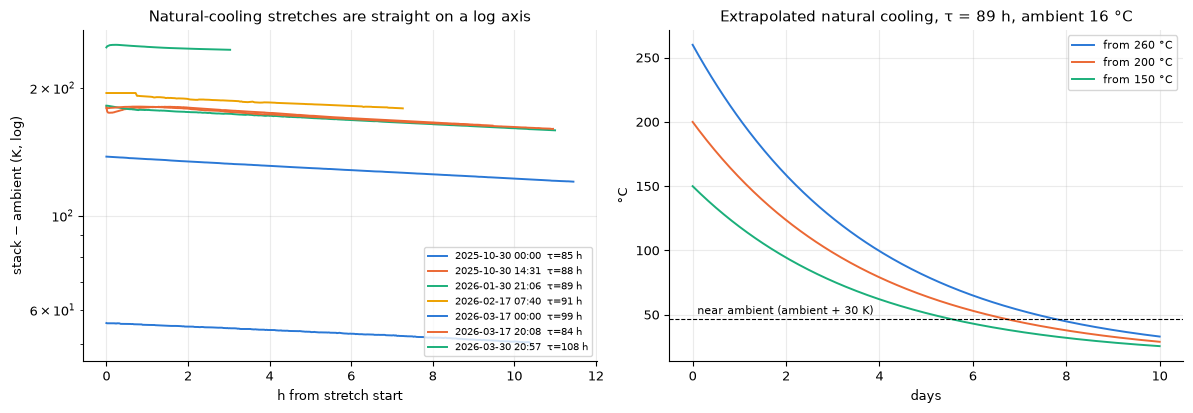

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
cols4 = list(SUB_COLORS.values())
for i, r in fits.iterrows():
    g = d.loc[r.start : r.end]
    g = g[nat.loc[g.index]]
    h = (g.index - g.index[0]).total_seconds() / 3600
    col = cols4[i % 4] if r.R2 >= 0.9 else "#9aa5b1"
    ax[0].plot(
        h,
        g.T_stack_C - r.T_amb_C,
        color=col,
        lw=1.4,
        label=f"{r.start:%Y-%m-%d %H:%M}  τ={r.tau_h:.0f} h",
    )
ax[0].set_yscale("log")
ax[0].set_xlabel("h from stretch start")
ax[0].set_ylabel("stack − ambient (K, log)")
ax[0].set_title("Natural-cooling stretches are straight on a log axis")
ax[0].legend(fontsize=7)
hh = np.linspace(0, 24 * 10, 300)
for T0, col in zip((260, 200, 150), cols4):
    ax[1].plot(
        hh / 24,
        ta + (T0 - ta) * np.exp(-hh / tau_med),
        color=col,
        label=f"from {T0} °C",
    )
ax[1].axhline(T_near, color="k", lw=0.8, ls="--")
ax[1].text(0.1, T_near + 4, "near ambient (ambient + 30 K)", fontsize=8)
ax[1].set_xlabel("days")
ax[1].set_ylabel("°C")
ax[1].legend(fontsize=8)
ax[1].set_title(
    f"Extrapolated natural cooling, τ = {tau_med:.0f} h, ambient {ta:.0f} °C"
)
fig.tight_layout()
fig.savefig(OUT / "cooling_tau.png", dpi=130)
plt.show()

## 6. Timings

### 6.1 Durations and clock times

Durations of episodes cut at a file edge are lower bounds. Clock times are given only for boundaries that are real
transitions (not a file edge).

In [14]:
tm = ce[
    [
        "episode_id",
        "start",
        "end",
        "duration_h",
        "starts_at_run_edge",
        "ends_at_run_edge",
        "prev_label",
        "next_stage",
    ]
].copy()
tm["enter_clock"] = tm.start.dt.strftime("%H:%M").where(
    ~tm.starts_at_run_edge, "file edge"
)
tm["leave_clock"] = tm.end.dt.strftime("%H:%M").where(~tm.ends_at_run_edge, "file edge")
both = ~tm.starts_at_run_edge & ~tm.ends_at_run_edge
print(
    f"Episodes: {len(tm)}; with both ends real transitions: {both.sum()} "
    f"(median {tm[both].duration_h.median():.1f} h, range "
    f"{tm[both].duration_h.min():.1f}–{tm[both].duration_h.max():.1f} h)"
)
print(
    f"Total plant-off time logged: {tm.duration_h.sum():.0f} h; at ambient "
    f"only: {len(s) / 60:.0f} h"
)
tm.to_csv(OUT / "timings.csv", index=False)
tm.drop(columns=["starts_at_run_edge", "ends_at_run_edge"])

Episodes: 16; with both ends real transitions: 3 (median 9.2 h, range 4.1–10.9 h)
Total plant-off time logged: 151 h; at ambient only: 78 h


,episode_id,start,end,duration_h,prev_label,next_stage,enter_clock,leave_clock
0,20251030_0000_off,2025-10-30 00:00:00,2025-10-30 11:29:00,11.483333,file edge,Start-up,file edge,11:29
1,20251030_1431_off,2025-10-30 14:31:00,2025-10-31 00:00:00,9.483333,"Start-up, Heat-up (EAPH on)",NaN,14:31,file edge
2,20251113_0000_off,2025-11-13 00:00:00,2025-11-13 10:47:00,10.783333,file edge,Start-up,file edge,10:47
3,20251118_0732_off,2025-11-18 07:32:00,2025-11-19 00:00:00,16.466667,"Shut-down, Cool-down (air flow on)",NaN,07:32,file edge
4,20260130_0000_off,2026-01-30 00:00:00,2026-01-30 10:10:00,10.166667,file edge,Start-up,file edge,10:10
5,20260130_2115_off,2026-01-30 21:15:00,2026-01-31 08:09:00,10.900000,"Shut-down, Cool-down (air flow on)",Start-up,21:15,08:09
6,20260206_0923_off,2026-02-06 09:23:00,2026-02-06 13:27:00,4.066667,"Shut-down, Cool-down (air flow on)",Start-up,09:23,13:27
7,20260213_0000_off,2026-02-13 00:00:00,2026-02-13 14:32:00,14.533333,file edge,Start-up,file edge,14:32
8,20260217_0742_off,2026-02-17 07:42:00,2026-02-17 16:56:00,9.233333,"Shut-down, Cool-down (air flow on)",Start-up,07:42,16:56
9,20260301_0000_off,2026-03-01 00:00:00,2026-03-01 09:05:00,9.083333,file edge,Start-up,file edge,09:05


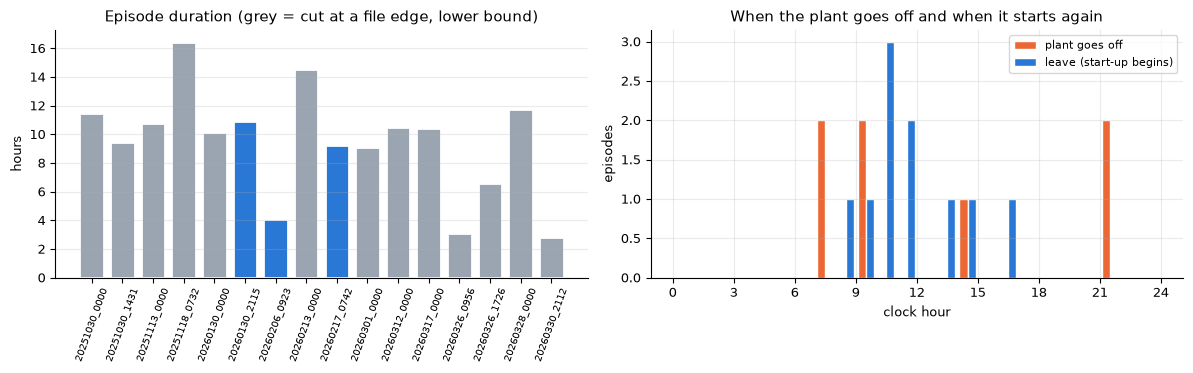

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
col = np.where(both, "#2a78d6", "#9aa5b1")
ax[0].bar(range(len(tm)), tm.duration_h, color=col, edgecolor="white", linewidth=2)
ax[0].set_xticks(range(len(tm)))
ax[0].set_xticklabels(tm.episode_id.str[:13], rotation=70, fontsize=7)
ax[0].set_ylabel("hours")
ax[0].set_title("Episode duration (grey = cut at a file edge, lower bound)")
ax[0].grid(axis="x", visible=False)
enter = tm.start[~tm.starts_at_run_edge]
leave = tm.end[~tm.ends_at_run_edge]
hb = np.arange(0, 25, 1)
ax[1].hist(
    [enter.dt.hour + enter.dt.minute / 60, leave.dt.hour + leave.dt.minute / 60],
    bins=hb,
    color=["#eb6834", "#2a78d6"],
    label=["plant goes off", "leave (start-up begins)"],
    edgecolor="white",
)
ax[1].set_xlabel("clock hour")
ax[1].set_ylabel("episodes")
ax[1].set_xticks(range(0, 25, 3))
ax[1].set_title("When the plant goes off and when it starts again")
ax[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "durations_clock.png", dpi=130)
plt.show()

### 6.2 Campaign calendar

Hours per stage on every logged day. Blank columns are days with no file; the plant state on those days is
unknown, so long off-periods between campaigns (e.g. 2025-11-19 → 2026-01-29) are not in the data at all.

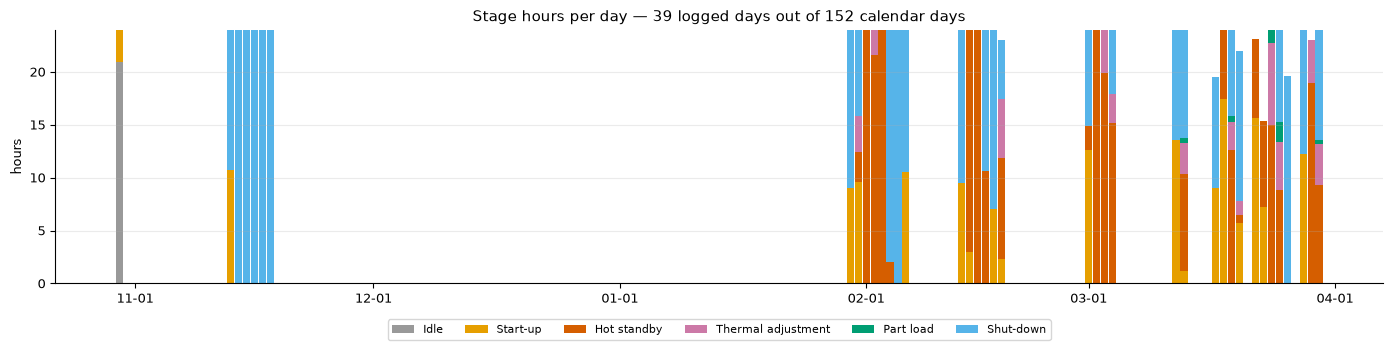

,after,before,missing_days
0,2025-10-30,2025-11-13,13.0
1,2025-11-18,2026-01-30,72.0
2,2026-02-06,2026-02-13,6.0
3,2026-02-18,2026-03-01,10.0
4,2026-03-04,2026-03-12,7.0
5,2026-03-13,2026-03-17,3.0
6,2026-03-20,2026-03-22,1.0
7,2026-03-26,2026-03-28,1.0


In [16]:
days = pd.date_range(d.index.min().normalize(), d.index.max().normalize())
hp = (
    d.groupby([d.index.normalize(), "stage"])
    .size()
    .unstack(fill_value=0)
    .reindex(days, fill_value=0)
    / 60
)
order = [x for x in ops.STAGES if x in hp.columns]
fig, ax = plt.subplots(figsize=(14, 3.6))
bottom = np.zeros(len(hp))
for st in order:
    ax.bar(
        hp.index, hp[st], bottom=bottom, width=0.9, color=ops.STAGE_COLORS[st], label=st
    )
    bottom += hp[st].values
logged = hp.sum(axis=1) > 0
ax.set_ylabel("hours")
ax.set_ylim(0, 24)
ax.legend(ncol=6, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.grid(axis="x", visible=False)
ax.set_title(
    f"Stage hours per day — {logged.sum()} logged days out of {len(days)} calendar days"
)
fig.tight_layout()
fig.savefig(OUT / "calendar.png", dpi=130)
plt.show()
gaps = pd.Series(logged.index[logged]).diff().dt.days.sub(1)
gap_tab = pd.DataFrame(
    {
        "after": pd.Series(logged.index[logged]).shift(),
        "before": pd.Series(logged.index[logged]),
        "missing_days": gaps,
    }
)
gap_tab[gap_tab.missing_days > 0].reset_index(drop=True)

## 7. Leaving the off state — order of signals at a start-up

For every plant-off episode followed directly by a Start-up (no file edge in between), the first minute each
signal switches on is measured relative to the end of the episode (0 = first Start-up minute). Window:
3 h before to 6 h after.

| Signal | On when |
|---|---|
| Air flow (FIRC 1.1.1 + 1.1.2) | > 50 ln/min |
| Air pressure at stack inlet `PIR_2_02` | > 1 |
| N₂ purge (FIRC 1.3) | > 1 ln/min |
| H₂ (FIRC 1.5) | > 0.5 ln/min |
| EAPH heater | > 0.2 kW |
| Stack warming | 20-min slope > +10 °C/h |


In [17]:
ON = {
    "air_flow > 50": lambda w: w.air_flow > 50,
    "PIR_2_02 > 1": lambda w: w.P_air_in > 1,
    "N2 > 1": lambda w: w.N2 > 1,
    "H2 > 0.5": lambda w: w.H2 > 0.5,
    "EAPH > 0.2 kW": lambda w: w.P_EAPH_kW > 0.2,
    "stack dT/dt > 10 °C/h": lambda w: w.dTdt_20min_C_per_h > 10,
}
ex = []
for _, r in ce[(ce.next_stage == "Start-up") & ~ce.ends_at_run_edge].iterrows():
    w = d.loc[r.end - pd.Timedelta("3h") : r.end + pd.Timedelta("6h")]
    row = {
        "episode_id": r.episode_id,
        "start-up begins": r.end.strftime("%Y-%m-%d %H:%M"),
        "T_stack_C": round(d.T_stack_C.asof(r.end), 1),
        "logger_gap_in_window": len(w) < 0.95 * 540,
    }
    for k, f in ON.items():
        on = f(w)
        row[k] = (on[on].index[0] - r.end).total_seconds() / 60 if on.any() else np.nan
    n2 = w.N2 > 1
    row["T_stack_at_N2_on_C"] = (
        round(w.T_stack_C[n2].iloc[0], 1) if n2.any() else np.nan
    )
    ex.append(row)
ex = pd.DataFrame(ex)
ex.to_csv(OUT / "startup_signal_order.csv", index=False)
print(
    "minutes relative to the first Start-up minute (negative = before; NaN = "
    "not seen in the window)"
)
ok = ~ex.logger_gap_in_window
print("median over start-ups without a logger gap:")
print(ex[ok][list(ON) + ["T_stack_at_N2_on_C"]].median().round(1).to_string())
ex

minutes relative to the first Start-up minute (negative = before; NaN = not seen in the window)
median over start-ups without a logger gap:
air_flow > 50             -3.0
PIR_2_02 > 1              -2.0
N2 > 1                   258.5
H2 > 0.5                 259.0
EAPH > 0.2 kW              0.0
stack dT/dt > 10 °C/h     33.0
T_stack_at_N2_on_C       210.0


,episode_id,start-up begins,T_stack_C,logger_gap_in_window,air_flow > 50,PIR_2_02 > 1,N2 > 1,H2 > 0.5,EAPH > 0.2 kW,stack dT/dt > 10 °C/h,T_stack_at_N2_on_C
0,20251030_0000_off,2025-10-30 11:29,139.5,False,-1.0,0.0,169.0,169.0,58.0,78.0,204.9
1,20251113_0000_off,2025-11-13 10:47,10.1,False,-10.0,-9.0,329.0,329.0,0.0,15.0,236.8
2,20260130_0000_off,2026-01-30 10:10,4.1,False,-10.0,-9.0,NaN,NaN,0.0,20.0,NaN
3,20260130_2115_off,2026-01-31 08:09,176.0,False,-2.0,-1.0,119.0,119.0,0.0,33.0,225.7
4,20260206_0923_off,2026-02-06 13:27,45.3,False,NaN,NaN,NaN,NaN,0.0,NaN,NaN
5,20260213_0000_off,2026-02-13 14:32,14.5,False,-3.0,-2.0,277.0,278.0,0.0,25.0,207.9
6,20260217_0742_off,2026-02-17 16:56,191.7,False,-30.0,-29.0,106.0,106.0,-28.0,34.0,229.5
7,20260301_0000_off,2026-03-01 09:05,27.5,False,-1.0,0.0,297.0,297.0,27.0,52.0,210.4
8,20260312_0000_off,2026-03-12 10:29,28.4,False,-1.0,0.0,296.0,296.0,29.0,56.0,209.5
9,20260328_0000_off,2026-03-28 11:45,37.1,False,-35.0,-34.0,240.0,240.0,0.0,28.0,192.5


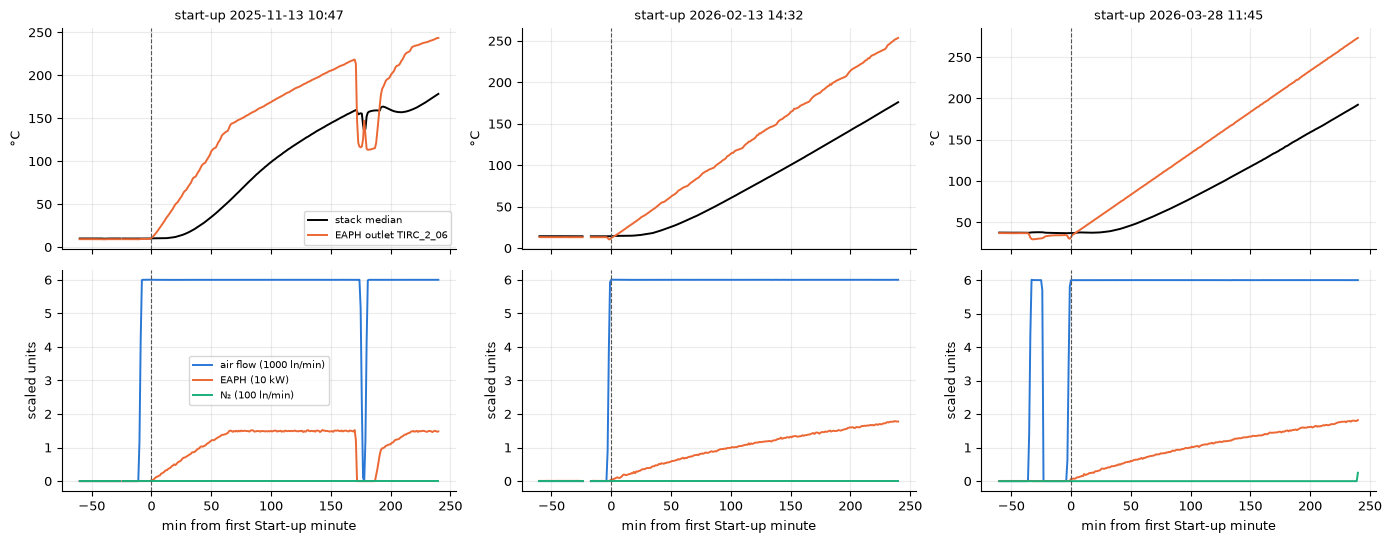

In [18]:
p = ex[~ex.logger_gap_in_window]["start-up begins"]
pick = p.iloc[[i for i in (1, 5, 9) if i < len(p)]]
fig, axs = plt.subplots(2, 3, figsize=(14, 5.5), sharex="col")
for j, t0 in enumerate(pd.to_datetime(pick)):
    w = d.loc[t0 - pd.Timedelta("1h") : t0 + pd.Timedelta("4h")]
    m = (w.index - t0).total_seconds() / 60
    axs[0, j].plot(m, w.T_stack_C, color="k", label="stack median")
    axs[0, j].plot(m, w.TIRC_2_06, color="#eb6834", label="EAPH outlet TIRC_2_06")
    axs[0, j].set_title(f"start-up {t0:%Y-%m-%d %H:%M}", fontsize=9)
    axs[0, j].set_ylabel("°C")
    axs[1, j].plot(
        m, w.air_flow / 1000, color="#2a78d6", label="air flow (1000 ln/min)"
    )
    axs[1, j].plot(m, w.P_EAPH_kW / 10, color="#eb6834", label="EAPH (10 kW)")
    axs[1, j].plot(m, w.N2 / 100, color="#1baf7a", label="N₂ (100 ln/min)")
    axs[1, j].set_xlabel("min from first Start-up minute")
    axs[1, j].set_ylabel("scaled units")
    for a in axs[:, j]:
        a.axvline(0, color="#555", lw=0.8, ls="--")
axs[0, 0].legend(fontsize=7)
axs[1, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUT / "startup_examples.png", dpi=130)
plt.show()

The lower panels put three signals on one scaled axis (air in 1000 ln/min, heater in 10 kW, N₂ in 100 ln/min) only
to show the order of switching; read the levels from the tables.

## 8. Signal baseline while the plant is off at ambient

Levels and noise during the **plant off at ambient** minutes: the input a synthetic at-rest generator needs. Noise σ
is the robust standard deviation (1.4826 × median absolute deviation) of the 1-min first difference, divided by √2.
It estimates white noise, ignores slow drift, and is not inflated by the few switching edges.


In [19]:
BASE = {
    "Stack median °C": "T_stack_C",
    "Stack TC spread K": "T_spread_K",
    "Ambient proxy °C": "T_amb_C",
    "Roof exhaust TIR_7_05 °C": "TIR_7_05",
    "String current A": "I_string_A",
    "Stack voltage (mean string) V": "V_stack_mean",
    "Stack power kW": "P_stack_kW",
    "EAPH power kW": "P_EAPH_kW",
    "Air pressure PIR_2_02": "P_air_in",
    "Air flow ln/min": "air_flow",
    "N2 flow ln/min": "N2",
    "H2 flow ln/min": "H2",
    "Fuel flow ln/min": "fuel",
    "Air supply pressure PIR_1_1_1 bar": "p_air_supply_bar",
    "N2 purge pressure PIR_1_3_2 bar": "p_N2_purge_bar",
    "H2 supply pressure PIR_1_5 bar": "p_H2_supply_bar",
    "Mains voltage V": "EIRC_2_01_ActV_rMas_MainsVoltage",
}
rows = {}
for name, col in BASE.items():
    x = s[col]
    dx = x.diff()[s.index.to_series().diff() == pd.Timedelta("1min")]
    rows[name] = {
        "p5": x.quantile(0.05),
        "median": x.median(),
        "p95": x.quantile(0.95),
        "noise_sigma": 1.4826 * (dx - dx.median()).abs().median() / np.sqrt(2),
        "share_nonzero": (x.abs() > 1e-3).mean(),
    }
base = pd.DataFrame(rows).T
base.to_csv(OUT / "signal_baseline.csv")
base.round(3)

,p5,median,p95,noise_sigma,share_nonzero
Stack median °C,6.100,23.075,45.300,0.016,0.998
Stack TC spread K,3.132,8.332,37.085,0.016,0.998
Ambient proxy °C,13.661,16.475,17.758,0.001,1.000
Roof exhaust TIR_7_05 °C,0.913,9.973,17.096,0.072,0.998
String current A,0.000,0.000,0.000,0.000,0.000
Stack voltage (mean string) V,0.000,0.026,0.065,0.001,0.812
Stack power kW,0.000,0.000,0.000,0.000,0.000
EAPH power kW,0.000,0.053,0.098,0.004,0.762
Air pressure PIR_2_02,0.262,0.317,0.358,0.005,0.998
Air flow ln/min,0.000,0.000,0.000,0.000,0.010


**Plant-off minutes where something is switched on.** These are short edges where the 15-minute smoothing in
`operating_states.py` absorbed the first or last minutes of a neighbouring block.


In [20]:
odd = c[(c.air_flow > 50) | (c.P_EAPH_kW > 0.2) | (c.N2 > 1)]
odd_tab = (
    odd.groupby([odd.episode_id, odd.index.floor("h")])
    .agg(
        minutes=("T_stack_C", "size"),
        air_flow_max=("air_flow", "max"),
        EAPH_max_kW=("P_EAPH_kW", "max"),
        N2_max=("N2", "max"),
    )
    .round(1)
)
print(f"{len(odd)} of {len(c):,} plant-off minutes ({len(odd) / len(c):.1%})")
odd_tab

61 of 9,082 plant-off minutes (0.7%)


,,minutes,air_flow_max,EAPH_max_kW,N2_max
episode_id,,,,,
20251030_0000_off,2025-10-30 11:00:00,1,1897.6,0.0,0.0
20251113_0000_off,2025-11-13 10:00:00,10,6003.1,0.0,0.0
20251118_0732_off,2025-11-18 07:00:00,1,500.8,0.0,0.0
20260130_0000_off,2026-01-30 10:00:00,10,6003.3,0.1,0.0
20260130_2115_off,2026-01-31 08:00:00,2,2818.9,0.1,0.0
20260206_0923_off,2026-02-06 09:00:00,3,195.2,0.0,29.5
20260213_0000_off,2026-02-13 14:00:00,3,5925.0,0.2,0.0
20260217_0742_off,2026-02-17 16:00:00,14,6002.6,7.2,0.0
20260301_0000_off,2026-03-01 09:00:00,1,260.2,0.1,0.0


## 9. Summary

In [21]:
summary = pd.Series(
    {
        "Plant-off minutes (Idle + Shut-down at rest)": (
            f"{len(c):,} ({len(c) / 60:.0f} h, {len(c) / len(d):.0%} of logged time)"
        ),
        "Episodes": f"{len(ce)} ({int(ce.cut_at_file_edge.sum())} cut at a file edge)",
        **{n: f"{(c.subtype == n).sum() / 60:.0f} h" for n in names},
        "Ambient proxy (at ambient, median)": f"{s.T_amb_C.median():.1f} °C",
        "Stack excess over ambient when at ambient (median)": (
            f"{s.excess_K.median():.1f} K"
        ),
        "Natural-cooling time constant τ (stack)": (
            f"{tau_med:.0f} h (range {good.tau_h.min():.0f}–{good.tau_h.max():.0f} h)"
        ),
        "Natural cooling 200 °C → near ambient (extrapolated)": (
            f"{tau_med * np.log((200 - ta) / ops.DT_AMBIENT) / 24:.1f} days"
        ),
    },
    name="value",
)
summary.to_frame()

,value
Plant-off minutes (Idle + Shut-down at rest),"9,082 (151 h, 17% of logged time)"
Episodes,16 (13 cut at a file edge)
Shut-down: plant off at ambient,78 h
Shut-down: natural-cooling tail,53 h
Idle: after a stopped heat-up,9 h
Idle: no history in the data,11 h
"Ambient proxy (at ambient, median)",16.5 °C
Stack excess over ambient when at ambient (median),6.5 K
Natural-cooling time constant τ (stack),89 h (range 84–108 h)
Natural cooling 200 °C → near ambient (extrapolated),6.7 days


### Findings

**How much and what kind**
- The plant is off for **151 h (17 %)** of the 39 logged days, in **16 episodes**. 13 of them are cut at a file edge, so
  the real off-periods were longer. The biggest gaps are not in the data at all (72 missing days between 2025-11-18
  and 2026-01-30, see §6.2). The old Cold / idle label held 162 h: the 11 h overnight pause of 2026-03-17/18 is now
  part of the Start-up (*heat-up interrupted*), the rest only changed names.
- **78 h (51 %) Shut-down, plant off at ambient**: stack 3–46 °C, median 6.5 K above the ambient proxy.
- **53 h (35 %) Shut-down, natural-cooling tail** (2026-01-30, 02-17, 03-17, 03-26, 03-28, 03-30). Most of it is a warm
  stack (up to 264 °C), but on 03-26 and 03-28 the stack sits flat at **38–47 °C** while the ambient proxy is only
  ~10–12 °C, so it stays just above the 30 K limit and counts as tail rather than at ambient.
- **21 h Idle, all on 2025-10-30**: 9.5 h after the heat-up that stopped at ~215 °C (afternoon) and 11.5 h in the
  first file (morning, stack at 155 °C, no history).

**The 30 K "near ambient" margin (§3)**
- At-ambient minutes sit −10 to +28 K from the proxy (p5–p95). The hours move little between 20 K (71 h) and 30 K
  (78 h); at **40 K** the flat 38–47 °C stretches of 03-26 / 03-28 join (97 h), and above that nothing changes.
  The gap between 30 and 40 K is exactly those late-March days with a cold proxy.

**Temperature**
- At ambient: stack median **23 °C** (range 3–46 °C), drifting −0.1 °C/h. The FPM supply-line probes read a steady
  **~16 °C**, but after several days off the stack goes **below** them (6 °C on 2026-01-30, 10 °C on 2025-11-13). The
  FPM probes sit in a conditioned space; the stack's own surroundings follow the outdoor-side roof exhaust probe
  `TIR_7_05` (1–11 °C on those days). **There is no true ambient sensor for the stack enclosure.**
- Thermocouple spread at ambient: median **8 K**, up to 37 K when one or two probes sit near ambient while the rest are
  still warm (the wide grey bands in §4.1).
- BOP parts cool faster than the stack. Reformer catalyst, afterburner and ERH carry only **~0.85×** the stack's
  excess heat. The roof exhaust and APH outlet are close to ambient (0.07–0.14×). The EAPH outlet (cathode inlet)
  tracks the stack (0.99×).

**Cooling physics**
- Heater off, air off: the stack follows Newton's law of cooling very closely (R² 0.93–1.00) with a time constant
  **τ ≈ 89 h** (84–108 h, 7 stretches: Idle, Shut-down tail and the 03-17/18 Start-up pause alike). Using the roof-exhaust ambient instead gives
  86 h, so the choice of ambient barely matters.
- BOP time constants: reformer / afterburner / ERH **29–37 h**, EAPH and recycle line **53–62 h**, stack **89 h**,
  EAPH outlet **99 h**.
- Consequence: natural cooling from 200 °C to near ambient (~46 °C) takes about **6.7 days** (5.6 days from 150 °C,
  7.8 days from 260 °C). No natural-cooling tail in the data gets there before the next start-up or the end of a file,
  so a Shut-down that starts warm ends at a **Start-up**, not at ambient.

**Timings**
- The 3 episodes with both ends observed last **4–11 h** (median 9 h). All others are lower bounds.
- Start-ups (the end of the off state) begin between **08:09 and 16:56**, mostly 09:00–12:00: day-shift starts.
  The plant goes off at any hour (07:32 to 21:15).

**Leaving the off state** (10 start-ups without a logger gap; median offsets)
1. **Air on first**, about **3 min** before the first Start-up minute (range 1–35 min). Stack-inlet pressure
   `PIR_2_02` follows 1 min later.
2. **EAPH heater on** at minute 0. It usually defines the label boundary. On 2025-10-30, 2026-03-01 and 03-12 the
   label starts with the air purge and the heater followed 27–58 min later.
3. **Stack starts warming** (> 10 °C/h) about **33 min** later. The stack lags the heater.
4. **N₂ and H₂ (forming gas) together**, about **4 h** later at a stack temperature of **~210 °C** (192–237 °C).
- Exception: 2026-02-06 13:27 is a "start-up" with the heater on but no air and no warming.

**Signal baseline at ambient**
- Current, stack power, fuel, POx air, N₂, H₂ and air flow are exactly 0. Stack voltage is ~0.03 V.
- EAPH reads a small off-state power of **~50 W** (p95 0.1 kW). Stack-inlet pressure `PIR_2_02` sits at an offset of
  **~0.32**, not 0. Supply pressures stay up: air ~5.5 bar, H₂ ~5.2 bar.
- Stack temperature noise is tiny (σ ≈ 0.02 K per minute), so a synthetic at-rest trace is essentially a smooth
  exponential plus offsets.
- 61 minutes (0.7 %) of the off hours already show air or heater on. These are smoothing edges at the start of a
  start-up, absorbed by the 15-min merge in `operating_states.py`.

### For the synthetic-data generator
| Parameter | Value |
|---|---|
| Idle / natural-cooling curve | T = T_amb + (T₀ − T_amb)·exp(−t / 89 h), τ 84–108 h |
| Label while cooling | Idle if no Shut-down before it, else Shut-down (natural cooling); Shut-down (at ambient) once T ≤ T_amb + 30 K |
| Ambient | outdoor-side (`TIR_7_05` level, 1–20 °C seasonal), not the FPM probes |
| Stack at ambient | 3–46 °C, drift ≈ −0.1 °C/h, noise σ ≈ 0.02 K/min |
| BOP during cool-down | (part − amb) ≈ 0.85 × (stack − amb); τ 29–62 h |
| Off-state offsets | EAPH ~50 W, `PIR_2_02` ~0.32, stack voltage ~0.03 V, flows 0 |
| Exit sequence | air → (+1 min) pressure → (+0…58 min) EAPH → (+34 min) warming → (+4 h, ~210 °C) N₂ + H₂ |
| Exit clock time | 07:00–17:00, mostly 09:00–12:00 |

### Open points
1. ~~Code the 50 °C rule?~~ Done 2026-10-14 in a revised form: Idle stage + near-ambient Shut-down (ambient + 30 K).
2. ~~Cooling after a stopped heat-up?~~ Decided: **Idle** (2025-10-30). A plant-off pause between two parts of one
   heat-up (2026-03-17/18) is **Start-up, heat-up interrupted (plant off)**.
3. **Margin 30 K or 40 K?** 40 K would move the flat 38–47 °C stretches of 2026-03-26 / 03-28 (19 h) from
   natural-cooling tail to at ambient. The stage stays Shut-down either way.
4. **Ambient sensor**: confirm what the FPM probes `TIR_1_*` and the roof exhaust `TIR_7_05` actually see. A
   container or outdoor temperature tag in the plant documentation would replace both proxies.
